In [1]:
import os
import xarray as xr, numpy as np, pandas as pd
import matplotlib.pyplot as plt, cartopy.crs as ccrs
import matplotlib.cm as cm, matplotlib.colors as mcolors
from matplotlib.patches import Patch
import cartopy.feature as cfeature

from functions import build_country_weights, verify_population_coverage, EU_MEMBERS,\
                        country_weights_dict, baseline_start, baseline_end, lat_to_str_dict, \
                        cider_inj_lats_popweighted, basepath, cpath, cider_combined, pop, \
                        countries_zip_path, select_eu_mode, reorient_netcdf

In [2]:
n_members = 500
newpath = basepath + f'{n_members}_members/' 

countries = country_weights_dict['countries_gdf']
eu_mode = 'aggregated'

## One-at-a-time sensitivity testing across 5 parameters

Test sensitivity to `buffer_months`, `tau`, `eval_months`, `k_setting`, and `injection_type` one parameter at a time

**Default parameter settings** 
- `buffer_months = 12`
- `tau = 12`
- `eval_months = 36`
- `k_setting = country_k_2050` (2050 ensemble-median first f-threshold crossing)
- `injection_type = single_lat` ("single latitude")

**Alternate levels tested** (each swapped in one at a time, others held at default):
- `buffer_months`: 6, 18
- `tau`: 6, 18
- `eval_months`: 24, 48
- `k_setting`: `country_k_2035` (2035 median version)
- `injection_type`: `uniform` ("global uniform")


In [3]:
## Default parameter settings 
default_params = dict(injection_type="single_lat",
                      k_setting="country_k_2050",
                      buffer=12, tau=12, eval_len=36)

## Alternate levels to test for each parameter
param_test_levels = {"buffer": [6, 18], "tau": [6, 18],
                     "eval_len": [24, 48], "k_setting": ["country_k_2035"],
                     "injection_type": ["uniform"]}

## labels used in plot legends 
label_lookup = {"single_lat": "Single latitude injection",
                "uniform": "Global uniform injection",
                "country_k_2050": "Country-specific k (2050)",
                "country_k_2035": "Country-specific k (2035)"}

## Generic loader: fetch the min-injection-rate dataset for one full parameter combination

Given a scenario's `(param_varied, level)`, this looks up its `.nc` file in `rc14_files` (explicit paths, since file names differ across scenarios), and applies `select_eu_mode`. Returns `None` if that combination hasn't been run yet

In [6]:
## RC'14 results files. Paths are relative to `newpath` (= .../Perceptions_2025/cleaned_code/500_members/).
## Keyed by (param_varied, level); ("default", None) is the shared default. File names are NOT uniform
## across scenarios (the default/uniform files have no "_2050" suffix; the 2035-k file has an
## "_EU_agg_nans_replaced" suffix), so every path is spelled out explicitly rather than built by rule.
rc14_files = {
    ("default", None):
        "results_buffer=12m_tau=12m_eval=36m_k_2050/single_lat_min_rates_country_k.nc",
    ("injection_type", "uniform"):
        "results_buffer=12m_tau=12m_eval=36m_k_2050/global_uniform_min_rates_country_k.nc",
    ("buffer", 6):
        "results_buffer=6m_tau=12m_eval=36m_k_2050/single_lat_min_rates_country_k_2050.nc",
    ("buffer", 18):
        "results_buffer=18m_tau=12m_eval=36m_k_2050/single_lat_min_rates_country_k_2050.nc",
    ("eval_len", 24):
        "results_buffer=12m_tau=12m_eval=24m_k_2050/single_lat_min_rates_country_k_2050.nc",
    ("eval_len", 48):
        "results_buffer=12m_tau=12m_eval=48m_k_2050/single_lat_min_rates_country_k_2050.nc",
    ("tau", 6):
        "results_buffer=12m_tau=6m_eval=36m_k_2050/single_lat_min_rates_country_k_2050.nc",
    ("tau", 18):
        "results_buffer=12m_tau=18m_eval=36m_k_2050/single_lat_min_rates_country_k_2050.nc",
    ("k_setting", "country_k_2035"):
        "results_buffer=12m_tau=12m_eval=36m/single_lat_min_rates_country_k_2035_EU_agg_nans_replaced.nc"}


def load_min_injection_dataset(param_varied, level):
    """
    Load + EU-fold the min_injection_rate Dataset for one scenario, looked up in `rc14_files`.
    Returns None (and prints a note) if the corresponding results file doesn't exist yet.
    """
    key = ("default", None) if param_varied == "default" else (param_varied, level)
    fpath = newpath + rc14_files[key]

    if not os.path.exists(fpath):
        print(f"  missing file: {fpath}")
        return None

    ds = xr.open_dataset(fpath)
    ds = select_eu_mode(ds, eu_mode)
    return ds


## Build scenario list


In [7]:
scenarios = []

def add_scenario(params, param_varied, level, is_default=False):
    """Load data for `params` and append a scenario dict; returns the scenario (or None if missing)."""
    ds = load_min_injection_dataset(param_varied, level)
    if ds is None:
        return None
    s = dict(param_varied=param_varied, level=level, is_default=is_default,
             data=ds["min_injection_rate"], **params)
    scenarios.append(s)
    return s

## Default scenario (shared baseline for every parameter's comparison)
default_scenario = add_scenario(default_params, param_varied="default", level=None, is_default=True)
assert default_scenario is not None, \
    "Default scenario data not found -- check default_params / the `rc14_files` paths"

## One-at-a-time alternates: swap in each level of each parameter, others stay at default
for param, levels in param_test_levels.items():
    for level in levels:
        params = {**default_params, param: level}
        add_scenario(params, param_varied=param, level=level)

print(f"\n{len(scenarios)} scenarios loaded (including default)")


9 scenarios loaded (including default)


In [9]:
expected = 1 + sum(len(levels) for levels in param_test_levels.values())  # 9 with current config (default + buffer x2, tau x2, eval_len x2, k x1, injection x1)
assert len(scenarios) == expected, (
    f"Expected {expected} RC'14 scenarios but only {len(scenarios)} loaded")

## 90th percentile min injection rate by country, per scenario

In [11]:
countries_of_interest = list(default_scenario['data'].country.values) ## All countries

country_short_names = {'Australia':'Australia',
                       'Bangladesh':'Bangladesh',
                       'Brazil':'Brazil',
                       'China':'China',
                       'Egypt':'Egypt',
                       'Ethiopia':'Ethiopia',
                       'European Union':'EU',
                       'India':'India',
                       'Indonesia':'Indonesia',
                       'Japan':'Japan',
                       'Nigeria':'Nigeria',
                       'Pakistan':'Pakistan',
                       'Russia':'Russia',
                       'Saudi Arabia':'Saudi Arabia',
                       'South Africa':'South Africa',
                       'United Kingdom':'UK',
                       'United States of America':'USA'}

for s in scenarios:
    da = s["data"]  # dims: (country, ensemble)
    p90_by_country = da.quantile(0.90, dim="ensemble")  # dims: (country,)
    s["p90_by_country"] = p90_by_country.sel(country=countries_of_interest)

## Assemble a long-format DataFrame for plotting

One row per (scenario, country)


In [12]:
def scenario_label(s):
    if s["is_default"]:
        return (f"Default (buffer=12, tau=12, eval_len=36m)")
    
    level_label = label_lookup.get(s["level"], s["level"])
    param_display = {"buffer": "buffer",
                     "tau": "tau",
                     "eval_len": "eval_len",
                     "k_setting": "k_setting",
                     "injection_type": "injection_type"}[s["param_varied"]]
    
    if s["param_varied"] in ("buffer", "tau", "eval_len"):
        return f"{param_display} = {s['level']}m"
    return f"{param_display} = {level_label}"

records = []
for s in scenarios:
    label = scenario_label(s)
    for country in countries_of_interest:
        val = float(s["p90_by_country"].sel(country=country).values)
        records.append(dict(
            scenario=label,
            param_varied=s["param_varied"],
            level=s["level"],
            country=country,
            country_label=country_short_names[country],
            p90_min_injection=val))

df = pd.DataFrame(records)
df

,scenario,param_varied,level,country,country_label,p90_min_injection
0,"Default (buffer=12, tau=12, eval_len=36m)",default,None,Australia,Australia,11.0
1,"Default (buffer=12, tau=12, eval_len=36m)",default,None,Bangladesh,Bangladesh,10.0
2,"Default (buffer=12, tau=12, eval_len=36m)",default,None,Brazil,Brazil,18.8
3,"Default (buffer=12, tau=12, eval_len=36m)",default,None,China,China,5.0
4,"Default (buffer=12, tau=12, eval_len=36m)",default,None,Egypt,Egypt,7.0
...,...,...,...,...,...,...
148,injection_type = Global uniform injection,injection_type,uniform,Russia,Russia,14.9
149,injection_type = Global uniform injection,injection_type,uniform,Saudi Arabia,Saudi Arabia,11.0
150,injection_type = Global uniform injection,injection_type,uniform,South Africa,South Africa,19.0
151,injection_type = Global uniform injection,injection_type,uniform,United Kingdom,UK,9.8


## Plot

In [13]:
## "Simple memory model" results
spath_root = newpath + 'simple_memory_model/'     # holds the 2035-start file
spath = spath_root + '2050/'                       # holds all the 2050 files

test = xr.open_dataset(spath + 'buffer=12m_3_test_years_2050.nc')
test

<xarray.Dataset> Size: 2kB
Dimensions:                  (country: 17, injection_type: 2)
Coordinates:
  * country                  (country) <U24 2kB 'Australia' ... 'United State...
  * injection_type           (injection_type) <U10 80B 'single_lat' 'uniform'
Data variables:
    min_injection_rate       (country, injection_type) float64 272B ...
    frac_cooler_at_min_rate  (country, injection_type) float64 272B ...

In [14]:
## M19: default is now 2050 start, fixed (stationary) baseline, 12m buffer, 3 test years, single_lat.
## Tests: buffer (6/18m), eval (2/4 test years), injection type ('uniform', via .sel below),
## moving baseline, and 2035 start. All 2050 files live in `spath`; the 2035-start file is in `spath_root`.
model_type = 'stationary_baseline'   # only used in the saved figure filenames
print(model_type)

b12_t3 = xr.open_dataset(spath + 'buffer=12m_3_test_years_2050.nc')      # default; also used for 'uniform'
b6_t3  = xr.open_dataset(spath + 'buffer=6m_3_test_years_2050.nc')
b18_t3 = xr.open_dataset(spath + 'buffer=18m_3_test_years_2050.nc')
b12_t2 = xr.open_dataset(spath + 'buffer=12m_2_test_years_2050.nc')     # 24m eval
b12_t4 = xr.open_dataset(spath + 'buffer=12m_4_test_years_2050.nc')     # 48m eval

b12_t3_moving = xr.open_dataset(spath + 'buffer=12m_3_test_years_moving_baseline_2050.nc')

## 2035-start version of the default (buffer=12m, eval=3yr)
b12_t3_2035 = xr.open_dataset(spath_root + '12m_buffer_3_test_years_0.9_cooler_all_countries.nc')


stationary_baseline


In [15]:
## ------------------------------------------------------------------
## Simple memory model ("M et al. '19"): build a scenario list + long-format
## DataFrame, parallel to the RC'14 `scenarios` / `df` built above.
##
## This model has no tau / k_setting parameters
## ------------------------------------------------------------------

def mem_scenario_label(param_varied, level, is_default=False):
    if is_default:
        return "M et al. '19 Default"
    if param_varied == "buffer":
        return f"M et al. '19 buffer = {level}m"
    if param_varied == "eval_len":
        return f"M et al. '19 eval_len = {level}m"
    if param_varied == "moving_baseline":
        return "M et al. '19 moving baseline"
    if param_varied == "deployment":
        return f"M et al. '19 deployment = {level}"
    return f"M et al. '19 injection_type = {level}"

mem_scenario_specs = [
    (True,  "default",         None,      "single_lat", b12_t3),
    (False, "buffer",          6,         "single_lat", b6_t3),
    (False, "buffer",          18,        "single_lat", b18_t3),
    (False, "eval_len",        24,        "single_lat", b12_t2),
    (False, "eval_len",        48,        "single_lat", b12_t4),
    (False, "injection_type",  "uniform", "uniform",    b12_t3),
    (False, "moving_baseline", None,      "single_lat", b12_t3_moving),
    (False, "deployment",      2035,      "single_lat", b12_t3_2035)]

mem_records = []
for is_default, param_varied, level, inj_type, ds in mem_scenario_specs:
    label = mem_scenario_label(param_varied, level, is_default=is_default)
    da = ds["min_injection_rate"].sel(injection_type=inj_type)
    
    for country in countries_of_interest:
        mem_records.append(dict(
            scenario=label,
            param_varied=param_varied if not is_default else "default",
            level=level,
            country=country,
            country_label=country_short_names[country],
            min_injection_rate=float(da.sel(country=country).values)))
        
assert len(mem_records) == len(mem_scenario_specs) * len(countries_of_interest), \
    "Not every M et al. '19 scenario/country combination produced a record -- check for missing data."

df_mem = pd.DataFrame(mem_records)
df_mem

,scenario,param_varied,level,country,country_label,min_injection_rate
0,M et al. '19 Default,default,None,Australia,Australia,9.0
1,M et al. '19 Default,default,None,Bangladesh,Bangladesh,10.0
2,M et al. '19 Default,default,None,Brazil,Brazil,15.0
3,M et al. '19 Default,default,None,China,China,4.0
4,M et al. '19 Default,default,None,Egypt,Egypt,5.0
...,...,...,...,...,...,...
131,M et al. '19 deployment = 2035,deployment,2035,Russia,Russia,13.0
132,M et al. '19 deployment = 2035,deployment,2035,Saudi Arabia,Saudi Arabia,5.0
133,M et al. '19 deployment = 2035,deployment,2035,South Africa,South Africa,11.0
134,M et al. '19 deployment = 2035,deployment,2035,United Kingdom,UK,16.0


In [16]:
cider_inj_lats_popweighted = xr.open_dataset(basepath + \
                                'cider_injection_latitudes_by_country_popweighted.nc')
for country in cider_inj_lats_popweighted.country.values:

    print(country, cider_inj_lats_popweighted.sel(country=country).nearest_cider_lat.values)

Antarctica -60.0
United Kingdom 60.0
New Zealand -30.0
Chile -30.0
Australia -30.0
Argentina -30.0
South Africa -30.0
France 30.0
Uruguay -30.0
Brazil -15.0
Namibia -15.0
Madagascar -15.0
Tonga -15.0
Mauritius -15.0
Lesotho -30.0
Mozambique -15.0
Fiji -15.0
Paraguay -30.0
eSwatini -30.0
Botswana -15.0
Peru -15.0
Bolivia -15.0
Zimbabwe -15.0
Vanuatu -15.0
Ecuador 0.0
Angola -15.0
Zambia -15.0
Samoa -15.0
United States of America 30.0
Malawi -15.0
Papua New Guinea 0.0
Kiribati 0.0
Comoros -15.0
Indonesia 0.0
Solomon Islands -15.0
Democratic Republic of the Congo 0.0
Seychelles 0.0
United Republic of Tanzania 0.0
East Timor -15.0
Tuvalu -15.0
São Tomé and Principe 0.0
Gabon 0.0
Ivory Coast 0.0
Ghana 0.0
Republic of the Congo 0.0
Kenya 0.0
Somalia 0.0
Sri Lanka 0.0
Nauru 0.0
Mexico 15.0
Liberia 0.0
Burundi 0.0
Colombia 0.0
Uganda 0.0
Maldives 0.0
Sierra Leone 15.0
Equatorial Guinea 0.0
Malaysia 0.0
Federated States of Micronesia 15.0
Venezuela 15.0
Guyana 0.0
Suriname 0.0
Cabo Verde 15.0
G

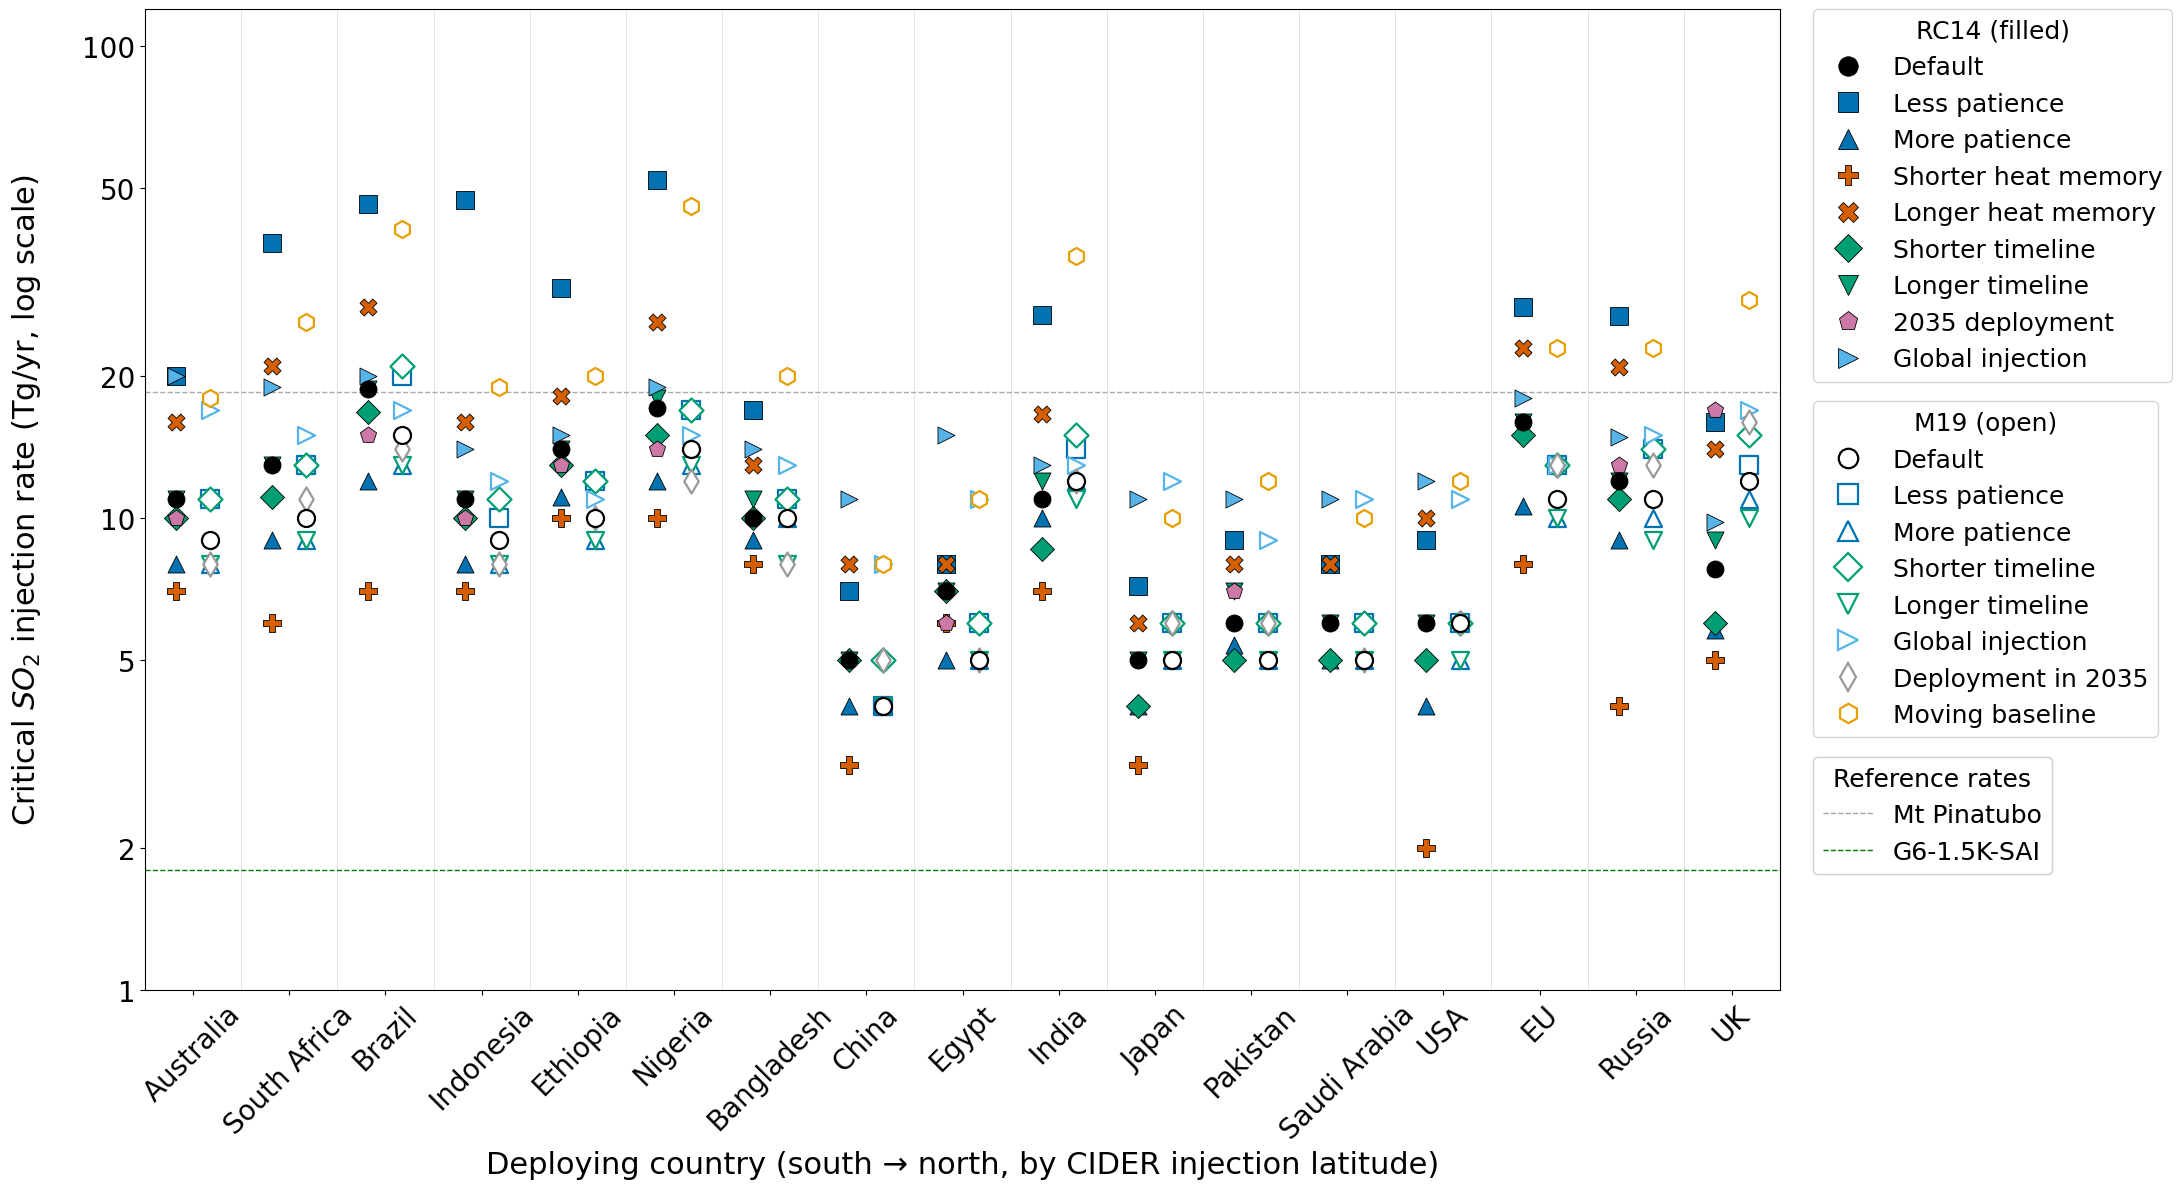

In [18]:
group_spacing = 1.7   # horizontal space between each country's pair of columns
col_offset = 0.3     # half the distance between a country's two columns (RC'14 vs M19)

## Order countries left-to-right by CIDER injection latitude
cider_lat_by_country = {c: float(cider_inj_lats_popweighted.sel(country=c).nearest_cider_lat.values)
                         for c in countries_of_interest}
country_order = sorted(countries_of_interest, key=lambda c: cider_lat_by_country[c])

x_center = {c: i * group_spacing for i, c in enumerate(country_order)}
x_rc  = {c: x_center[c] - col_offset for c in country_order}
x_mem = {c: x_center[c] + col_offset for c in country_order}

## Fixed marker for every (param, level) combination, both models
full_marker_map = {("default", None): 'o',
                    ("buffer", 6): 's',
                    ("buffer", 18): '^',
                    ("tau", 6): 'P',
                    ("tau", 18): 'X',
                    ("eval_len", 24): 'D',
                    ("eval_len", 48): 'v',
                    ("k_setting", "low_k"): '*',
                    ("k_setting", "high_k"): '<',
                    ("k_setting", "country_k_2035"): 'p',   # RC'14 only
                    ("deployment", 2035): 'd',                 # M'19 only
                    ("injection_type", "uniform"): '>',
                    ("moving_baseline", None): 'h'}

shared_marker_map = {k: v for k, v in full_marker_map.items()
                      if k in {("default", None), ("buffer", 6), ("buffer", 18),
                               ("eval_len", 24), ("eval_len", 48), ("injection_type", "uniform"),
                               ("moving_baseline", None), ("deployment", 2035)}}

scenario_order = list(dict.fromkeys(df["scenario"]))
marker_map = {}
for scen in scenario_order:
    sub = df[df["scenario"] == scen].iloc[0]
    key = ("default", None) if sub["param_varied"] == "default" else (sub["param_varied"], sub["level"])
    marker_map[scen] = full_marker_map[key]   # KeyError if an unexpected (param, level) shows up

mem_scenario_order = list(dict.fromkeys(df_mem["scenario"]))
mem_marker_map = {}
for scen in mem_scenario_order:
    sub = df_mem[df_mem["scenario"] == scen].iloc[0]
    key = ("default", None) if sub["param_varied"] == "default" else (sub["param_varied"], sub["level"])
    mem_marker_map[scen] = shared_marker_map.get(key, 'o')

## Plot "Default" last (on top) in each column so it's never hidden behind a nearby marker
default_label = scenario_label(default_scenario)
mem_default_label = mem_scenario_label(None, None, is_default=True)
scenario_order = [s for s in scenario_order if s != default_label] + [default_label]
mem_scenario_order = [s for s in mem_scenario_order if s != mem_default_label] + [mem_default_label]

## Okabe-Ito colorblind-safe palette (Okabe & Ito, 2008)
param_colors = {
    "default": "#000000",         # black
    "buffer": "#0072B2",          # blue
    "tau": "#D55E00",             # vermillion
    "eval_len": "#009E73",        # bluish green
    "k_setting": "#CC79A7",       # reddish purple
    "injection_type": "#56B4E9",  # sky blue
    "moving_baseline": "#E69F00", # orange
    "deployment": "#999999",}     # gray


fig, ax = plt.subplots(figsize=(18, 12))

## RC'14 -- filled markers, left column
for scen in scenario_order:
    sub = df[df["scenario"] == scen]
    param_varied = sub["param_varied"].iloc[0]
    ax.scatter(
        [x_rc[c] for c in sub["country"]],
        sub["p90_min_injection"],
        marker=marker_map[scen],
        color=param_colors.get(param_varied, "gray"),
        s=150, edgecolor="k", linewidth=0.6, zorder=3)

## M et al. '19 -- open/hollow markers, right column 
for scen in mem_scenario_order:
    sub = df_mem[df_mem["scenario"] == scen]
    param_varied = sub["param_varied"].iloc[0]
    color = param_colors.get(param_varied, "gray")
    ax.scatter(
        [x_mem[c] for c in sub["country"]],
        sub["min_injection_rate"],
        marker=mem_marker_map[scen],
        facecolor="white",
        edgecolor=color, linewidth=1.6, s=150, zorder=3)

## Faint separators between each country's pair of columns
for i in range(len(country_order) - 1):
    ax.axvline(x_center[country_order[i]] + group_spacing / 2,
               color="gray", linewidth=0.6, linestyle="-", alpha=0.25, zorder=1)

ax.set_xticks(list(x_center.values()))
ax.set_xticklabels([country_short_names[c] for c in country_order], fontsize=20, rotation=45)
ax.set_xlim(-group_spacing / 2, (len(country_order) - 1) * group_spacing + group_spacing / 2)

ax.set_yscale("log")
yticks = [1, 2, 5, 10, 20, 50, 100]
ax.set_yticks(yticks)
ax.set_yticklabels([str(t) for t in yticks], fontsize=20)
ax.minorticks_off()
ax.set_ylim(1, 120)   

ax.set_ylabel("Critical $SO_{2}$ injection rate (Tg/yr, log scale)\n",
              fontsize=22)
# ax.set_title("Sensitivity of minimum $SO_{2}$ injection rate\n", fontsize=24)
ax.set_xlabel('Deploying country (south \u2192 north, by CIDER injection latitude)', fontsize=22)

## Manual legends
## ------------------------------------------------------------------
from matplotlib.lines import Line2D

## filled markers  for RC'14
rc14_legend_entries = [
    dict(label="Default", marker='o', color=param_colors["default"]),
    dict(label="Less patience",               marker='s', color=param_colors["buffer"]),
    dict(label="More patience",              marker='^', color=param_colors["buffer"]),
    dict(label="Shorter heat memory",                  marker='P', color=param_colors["tau"]),
    dict(label="Longer heat memory",                 marker='X', color=param_colors["tau"]),
    dict(label="Shorter timeline",            marker='D', color=param_colors["eval_len"]),
    dict(label="Longer timeline",            marker='v', color=param_colors["eval_len"]),
    dict(label="2035 deployment",     marker='p', color=param_colors["k_setting"]),
    dict(label="Global injection",  marker='>', color=param_colors["injection_type"])]

## open/hollow markers  for M et al. '19
mem_legend_entries = [
    dict(label="Default", marker='o', color=param_colors["default"]),
    dict(label="Less patience",               marker='s', color=param_colors["buffer"]),
    dict(label="More patience",              marker='^', color=param_colors["buffer"]),
    dict(label="Shorter timeline",            marker='D', color=param_colors["eval_len"]),
    dict(label="Longer timeline",            marker='v', color=param_colors["eval_len"]),
    dict(label="Global injection",  marker='>', color=param_colors["injection_type"]),
    dict(label="Deployment in 2035", marker='d', color=param_colors["deployment"]),
    dict(label="Moving baseline",   marker='h', color=param_colors["moving_baseline"])]

def make_handle(marker, color, filled):
    return Line2D(
        [], [], linestyle="None", marker=marker,
        markersize=14,
        markerfacecolor=color if filled else "white",
        markeredgecolor="k" if filled else color,
        markeredgewidth=0.6 if filled else 1.6)

rc_handles = [make_handle(e["marker"], e["color"], filled=True) for e in rc14_legend_entries]
rc_labels  = [e["label"] for e in rc14_legend_entries]

mem_handles = [make_handle(e["marker"], e["color"], filled=False) for e in mem_legend_entries]
mem_labels  = [e["label"] for e in mem_legend_entries]

## Reference injection rates
pinatubo_line = ax.axhline(18.5, linewidth=1, linestyle='--', color='darkgrey', label='Mt Pinatubo')
g6_line       = ax.axhline(1.8,  linewidth=1, linestyle='--', color='green',    label='G6-1.5K-SAI')

plt.tight_layout()

## Stack the three legends vertically in the margin to the right of the plot
legend_specs = [(rc_handles,  rc_labels,  "RC14 (filled)"),
                (mem_handles, mem_labels, "M19 (open)"),
                ([pinatubo_line, g6_line], ["Mt Pinatubo", "G6-1.5K-SAI"], "Reference rates")]
legend_gap = 0.02    # vertical gap between stacked legends, in axes-fraction units
y_top = 1.0
for handles, labels, title in legend_specs:
    leg = ax.legend(handles, labels, title=title,
                    bbox_to_anchor=(1.02, y_top), loc="upper left", borderaxespad=0,
                    fontsize=18, title_fontsize=18, frameon=True)
    ax.add_artist(leg)      
    leg.set_clip_on(False)   
    fig.canvas.draw()        
    bb = leg.get_window_extent().transformed(ax.transAxes.inverted())
    y_top = bb.y0 - legend_gap

plt.savefig(newpath + f'Sensitivity_test_2050_default_{model_type}_log_scale.pdf', bbox_inches='tight')
plt.savefig(newpath + f'Sensitivity_test_2050_default_{model_type}_log_scale.png', bbox_inches='tight')

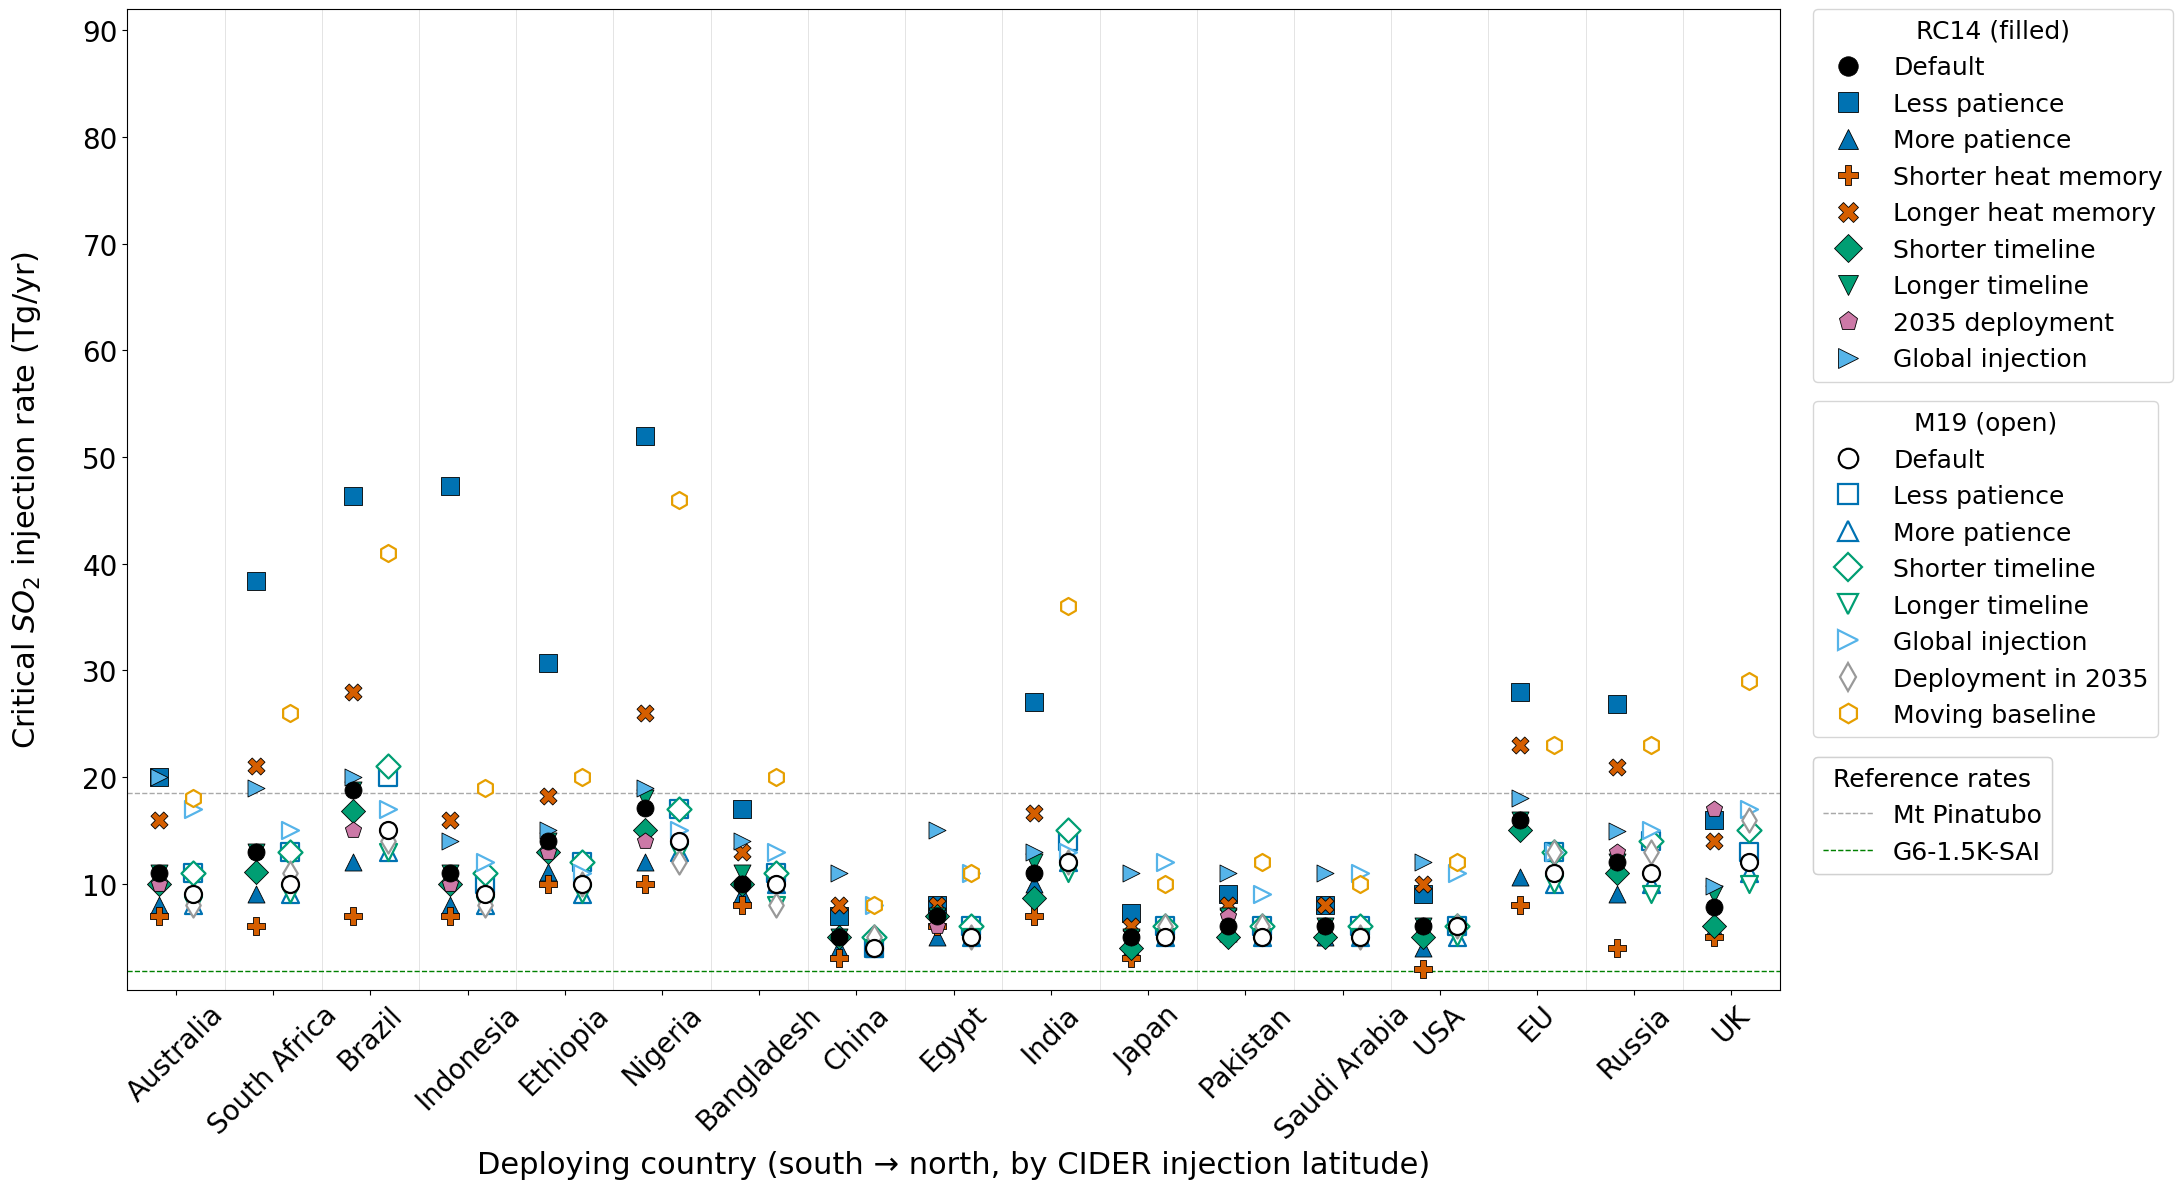

In [19]:
## Linear scale

group_spacing = 1.7   # horizontal space between each country's pair of columns
col_offset = 0.3     # half the distance between a country's two columns (RC'14 vs M19)

## Order countries left-to-right by CIDER injection latitude: furthest south on the far
## left, furthest north on the far right (uses the same values loaded in the cell above).
cider_lat_by_country = {c: float(cider_inj_lats_popweighted.sel(country=c).nearest_cider_lat.values)
                         for c in countries_of_interest}
country_order = sorted(countries_of_interest, key=lambda c: cider_lat_by_country[c])

x_center = {c: i * group_spacing for i, c in enumerate(country_order)}
x_rc  = {c: x_center[c] - col_offset for c in country_order}
x_mem = {c: x_center[c] + col_offset for c in country_order}


## Fixed marker for every (param, level) combination -- both models. This is the single
## source of truth for markers; it does NOT depend on which scenarios actually loaded,
## so a missing results file just means that marker is absent from the plot, never that
## markers shift and desync from the hardcoded legend below.
full_marker_map = {("default", None): 'o',
                    ("buffer", 6): 's',
                    ("buffer", 18): '^',
                    ("tau", 6): 'P',
                    ("tau", 18): 'X',
                    ("eval_len", 24): 'D',
                    ("eval_len", 48): 'v',
                    ("k_setting", "low_k"): '*',
                    ("k_setting", "high_k"): '<',
                    ("k_setting", "country_k_2035"): 'p',   # RC'14 only
                    ("deployment", 2035): 'd',                 # M'19 only
                    ("injection_type", "uniform"): '>',
                    ("moving_baseline", None): 'h'}

shared_marker_map = {k: v for k, v in full_marker_map.items()
                      if k in {("default", None), ("buffer", 6), ("buffer", 18),
                               ("eval_len", 24), ("eval_len", 48), ("injection_type", "uniform"),
                               ("moving_baseline", None), ("deployment", 2035)}}

scenario_order = list(dict.fromkeys(df["scenario"]))
marker_map = {}
for scen in scenario_order:
    sub = df[df["scenario"] == scen].iloc[0]
    key = ("default", None) if sub["param_varied"] == "default" else (sub["param_varied"], sub["level"])
    marker_map[scen] = full_marker_map[key]   # KeyError if an unexpected (param, level) shows up

mem_scenario_order = list(dict.fromkeys(df_mem["scenario"]))
mem_marker_map = {}
for scen in mem_scenario_order:
    sub = df_mem[df_mem["scenario"] == scen].iloc[0]
    key = ("default", None) if sub["param_varied"] == "default" else (sub["param_varied"], sub["level"])
    mem_marker_map[scen] = shared_marker_map.get(key, 'o')

## Plot "Default" last (on top) in each column so it's never hidden behind a nearby marker
default_label = scenario_label(default_scenario)
mem_default_label = mem_scenario_label(None, None, is_default=True)
scenario_order = [s for s in scenario_order if s != default_label] + [default_label]
mem_scenario_order = [s for s in mem_scenario_order if s != mem_default_label] + [mem_default_label]

## Okabe-Ito colorblind-safe palette (Okabe & Ito, 2008)
param_colors = {
    "default": "#000000",         # black
    "buffer": "#0072B2",          # blue
    "tau": "#D55E00",             # vermillion
    "eval_len": "#009E73",        # bluish green
    "k_setting": "#CC79A7",       # reddish purple
    "injection_type": "#56B4E9",  # sky blue
    "moving_baseline": "#E69F00", # orange
    "deployment": "#999999",}     # gray


fig, ax = plt.subplots(figsize=(18, 12))

## RC'14 -- filled markers, left column of each country pair
for scen in scenario_order:
    sub = df[df["scenario"] == scen]
    param_varied = sub["param_varied"].iloc[0]
    ax.scatter(
        [x_rc[c] for c in sub["country"]],
        sub["p90_min_injection"],
        marker=marker_map[scen],
        color=param_colors.get(param_varied, "gray"),
        s=150, edgecolor="k", linewidth=0.6, zorder=3)

## M et al. '19 -- open/hollow markers, right column of each country pair
for scen in mem_scenario_order:
    sub = df_mem[df_mem["scenario"] == scen]
    param_varied = sub["param_varied"].iloc[0]
    color = param_colors.get(param_varied, "gray")
    ax.scatter(
        [x_mem[c] for c in sub["country"]],
        sub["min_injection_rate"],
        marker=mem_marker_map[scen],
        facecolor="white",
        edgecolor=color, linewidth=1.6, s=150, zorder=3)

## Faint separators between each country's pair of columns
for i in range(len(country_order) - 1):
    ax.axvline(x_center[country_order[i]] + group_spacing / 2,
               color="gray", linewidth=0.6, linestyle="-", alpha=0.25, zorder=1)

ax.set_xticks(list(x_center.values()))
ax.set_xticklabels([country_short_names[c] for c in country_order], fontsize=20, rotation=45)
ax.set_xlim(-group_spacing / 2, (len(country_order) - 1) * group_spacing + group_spacing / 2)
# # ax.grid(axis="y", alpha=0.3, zorder=0)
yticks = [10, 20, 30, 40, 50, 60, 70, 80, 90]
ax.set_yticks(yticks)
ax.set_yticklabels([str(tick) for tick in yticks], fontsize=20)
ax.set_ylim(0, 92)

ax.set_ylabel("Critical $SO_{2}$ injection rate (Tg/yr)\n",
              fontsize=22)
# ax.set_title("Sensitivity of minimum $SO_{2}$ injection rate\n", fontsize=24)
ax.set_xlabel('Deploying country (south \u2192 north, by CIDER injection latitude)', fontsize=22)

## ------------------------------------------------------------------
## Manual legends: edit these two lists directly to control exactly what shows up, in what order, 
## and how it's labeled -- independent of which scenarios happen to be in `df` / `df_mem`. Pull 
## marker/color from the maps above to stay in sync with what's actually plotted, or hardcode
## your own if you want the legend fully decoupled from the data.
## ------------------------------------------------------------------
from matplotlib.lines import Line2D

## filled markers -- one row per legend entry you want to show for RC'14
rc14_legend_entries = [
    dict(label="Default", marker='o', color=param_colors["default"]),
    dict(label="Less patience",               marker='s', color=param_colors["buffer"]),
    dict(label="More patience",              marker='^', color=param_colors["buffer"]),
    dict(label="Shorter heat memory",                  marker='P', color=param_colors["tau"]),
    dict(label="Longer heat memory",                 marker='X', color=param_colors["tau"]),
    dict(label="Shorter timeline",            marker='D', color=param_colors["eval_len"]),
    dict(label="Longer timeline",            marker='v', color=param_colors["eval_len"]),
    dict(label="2035 deployment",     marker='p', color=param_colors["k_setting"]),
    dict(label="Global injection",  marker='>', color=param_colors["injection_type"])]

## open/hollow markers -- one row per legend entry you want to show for M et al. '19
mem_legend_entries = [
    dict(label="Default", marker='o', color=param_colors["default"]),
    dict(label="Less patience",               marker='s', color=param_colors["buffer"]),
    dict(label="More patience",              marker='^', color=param_colors["buffer"]),
    dict(label="Shorter timeline",            marker='D', color=param_colors["eval_len"]),
    dict(label="Longer timeline",            marker='v', color=param_colors["eval_len"]),
    dict(label="Global injection",  marker='>', color=param_colors["injection_type"]),
    dict(label="Deployment in 2035", marker='d', color=param_colors["deployment"]),
    dict(label="Moving baseline",   marker='h', color=param_colors["moving_baseline"])]

def make_handle(marker, color, filled):
    return Line2D(
        [], [], linestyle="None", marker=marker,
        markersize=14,
        markerfacecolor=color if filled else "white",
        markeredgecolor="k" if filled else color,
        markeredgewidth=0.6 if filled else 1.6)

rc_handles = [make_handle(e["marker"], e["color"], filled=True) for e in rc14_legend_entries]
rc_labels  = [e["label"] for e in rc14_legend_entries]

mem_handles = [make_handle(e["marker"], e["color"], filled=False) for e in mem_legend_entries]
mem_labels  = [e["label"] for e in mem_legend_entries]

## Reference injection rates (drawn once; handles are kept for their own legend)
pinatubo_line = ax.axhline(18.5, linewidth=1, linestyle='--', color='darkgrey', label='Mt Pinatubo')
g6_line       = ax.axhline(1.8,  linewidth=1, linestyle='--', color='green',    label='G6-1.5K-SAI')

## Lay out the axes first, THEN add legends outside, so tight_layout doesn't shrink the plot
## to make room for them. savefig(bbox_inches="tight") below still includes the legends.
plt.tight_layout()

## Stack the three legends vertically in the margin to the right of the plot. Each legend is
## anchored just below the previous one, using its rendered height, so spacing stays correct
## even if you add/remove entries or change font sizes.
legend_specs = [(rc_handles,  rc_labels,  "RC14 (filled)"),
                (mem_handles, mem_labels, "M19 (open)"),
                ([pinatubo_line, g6_line], ["Mt Pinatubo", "G6-1.5K-SAI"], "Reference rates")]
legend_gap = 0.02    # vertical gap between stacked legends, in axes-fraction units
y_top = 1.0
for handles, labels, title in legend_specs:
    leg = ax.legend(handles, labels, title=title,
                    bbox_to_anchor=(1.02, y_top), loc="upper left", borderaxespad=0,
                    fontsize=18, title_fontsize=18, frameon=True)
    ax.add_artist(leg)       # so the next ax.legend() call doesn't replace this one
    leg.set_clip_on(False)   # add_artist clips to the axes box, which hides legends placed outside it
    fig.canvas.draw()        # needed to get the legend's true rendered size
    bb = leg.get_window_extent().transformed(ax.transAxes.inverted())
    y_top = bb.y0 - legend_gap

plt.savefig(newpath + f'Sensitivity_test_2050_default_{model_type}.pdf', bbox_inches='tight')
plt.savefig(newpath + f'Sensitivity_test_2050_default_{model_type}.png', bbox_inches='tight')